# 05 — Model Comparison and Uncertainty
Combine the univariate and multivariate test results and construct a simple empirical uncertainty band for the best one-month-ahead univariate model. The band is an approximate residual-bootstrap interval, not a formal calibrated prediction interval.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_FILE = Path("../data/lithium_consolidated_monthly.csv")
TARGET = "Selected lithium carbonate price (CNY/t)"
JAPAN_INDEX = "Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100"
RANDOM_STATE = 42

df = pd.read_csv(DATA_FILE)
df["Month"] = pd.to_datetime(df["Month"])
df = df.sort_values("Month").drop_duplicates("Month").set_index("Month").asfreq("MS")
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

EXCLUDED = {
    TARGET, "Selected target source",
    "Lithium carbonate price (CNY/metric tonne)",
    "China spot lithium carbonate price (CNY/t) - CSV",
    "OLD - faulty cobalt settlement series (constant; excluded)",
    "China spot price open (CNY/t) - CSV",
    "China spot price high (CNY/t) - CSV",
    "China spot price low (CNY/t) - CSV",
    "China spot price volume (CSV)",
    "China spot price change (%) - CSV",
}
ALL_PREDICTORS = [c for c in df.select_dtypes(include=np.number).columns if c not in EXCLUDED]

def make_supervised(horizon=1, n_lags=6, exog_cols=None):
    """At month t, use target/predictor observations through t to predict target at t+h."""
    X = pd.DataFrame(index=df.index)
    for lag in range(0, n_lags):
        X[f"target_lag_{lag}"] = df[TARGET].shift(lag)
    if exog_cols:
        for col in exog_cols:
            for lag in range(1, n_lags + 1):
                X[f"{col}_lag_{lag}"] = pd.to_numeric(df[col], errors="coerce").shift(lag)
    y = df[TARGET].shift(-horizon).rename("target")
    data = X.join(y).dropna(subset=["target"])
    # Do not require every optional predictor to be present. Missing features are imputed within each training fold.
    return data.drop(columns="target"), data["target"]

def split_time(X, y, test_fraction=0.2):
    split = int(len(X) * (1-test_fraction))
    return X.iloc[:split], X.iloc[split:], y.iloc[:split], y.iloc[split:]

def model_bank():
    return {
        "Linear Regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression()),
        "Ridge": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10)),
        "KNN": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), KNeighborsRegressor(n_neighbors=5)),
        "SVR": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), SVR(C=10, epsilon=0.1)),
        "Random Forest": make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE)),
        "Gradient Boosting": make_pipeline(SimpleImputer(strategy="median"), GradientBoostingRegressor(random_state=RANDOM_STATE)),
    }

def score_predictions(y_true, pred):
    return {"MAE": mean_absolute_error(y_true, pred),
            "RMSE": mean_squared_error(y_true, pred)**0.5,
            "R2": r2_score(y_true, pred)}

## 1. Load benchmark results

In [2]:
uni_path = Path("../results/univariate_model_comparison.csv")
multi_path = Path("../results/multivariate_model_comparison.csv")
if not (uni_path.exists() and multi_path.exists()):
    raise FileNotFoundError("Run notebooks 03 and 04 first so their result CSV files exist.")
uni = pd.read_csv(uni_path); multi = pd.read_csv(multi_path)
uni["Approach"] = "Univariate"
multi["Approach"] = multi["Feature set"]
comparison = pd.concat([
    uni[["Approach","Horizon (months)","Model","MAE","RMSE","R2"]],
    multi[["Approach","Horizon (months)","Model","MAE","RMSE","R2"]]
], ignore_index=True)
display(comparison.sort_values(["Horizon (months)","RMSE"]))

,Approach,Horizon (months),Model,MAE,RMSE,R2
0,Univariate,1,Random Forest,1.963636e+04,2.814084e+04,0.761251
1,Univariate,1,Gradient Boosting,2.035393e+04,2.939133e+04,0.739561
2,Univariate,1,Linear Regression,2.736122e+04,4.338931e+04,0.432413
3,Univariate,1,Ridge,3.709751e+04,5.311257e+04,0.149525
24,Multivariate — with Japan index,1,Gradient Boosting,5.499741e+04,5.948784e+04,-0.066899
...,...,...,...,...,...,...
23,Univariate,12,Linear Regression,1.876691e+05,2.712468e+05,-30.298735
70,Multivariate — without Japan index,12,Ridge,4.585858e+05,4.901995e+05,-101.221775
64,Multivariate — with Japan index,12,Ridge,4.870139e+05,5.153051e+05,-111.960493
71,Multivariate — without Japan index,12,Linear Regression,6.799708e+05,7.284336e+05,-224.723936


## 2. Best model per approach and horizon

In [3]:
best = comparison.loc[comparison.groupby(["Approach","Horizon (months)"])["RMSE"].idxmin()]
display(best.sort_values(["Horizon (months)","RMSE"]))
best.to_csv("../results/best_model_by_approach_and_horizon.csv", index=False)

,Approach,Horizon (months),Model,MAE,RMSE,R2
0,Univariate,1,Random Forest,19636.357420,28140.839935,0.761251
24,Multivariate — with Japan index,1,Gradient Boosting,54997.410647,59487.841531,-0.066899
30,Multivariate — without Japan index,1,Gradient Boosting,82480.687833,87420.565458,-1.304063
6,Univariate,3,Gradient Boosting,48434.612614,76679.145576,-0.772644
36,Multivariate — with Japan index,3,SVR,74904.789898,94485.765947,-1.691534
42,Multivariate — without Japan index,3,SVR,74905.887302,94486.570874,-1.691580
12,Univariate,6,Gradient Boosting,62236.752527,80219.848690,-1.076572
48,Multivariate — with Japan index,6,SVR,71910.872144,90939.901824,-1.668654
54,Multivariate — without Japan index,6,SVR,71912.754111,90941.345121,-1.668739
18,Univariate,12,KNN,46902.900000,63489.862135,-0.714772


## 3. Residual bootstrap example for one-month univariate forecast

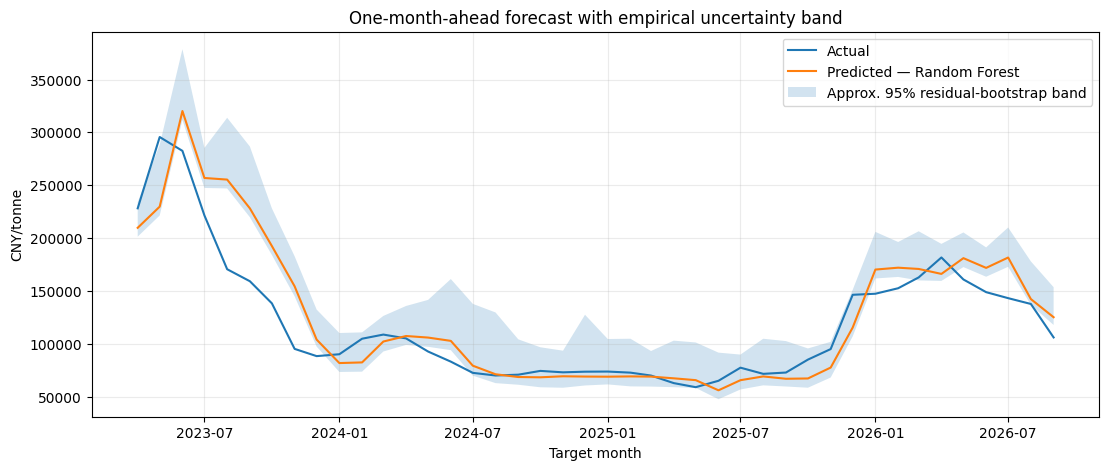

Empirical test coverage: 0.619


In [4]:
# Refit the best one-month univariate model on the chronological training segment.
uni_1 = uni[uni["Horizon (months)"]==1].sort_values("RMSE")
best_name = uni_1.iloc[0]["Model"]
X, y = make_supervised(horizon=1, n_lags=12, exog_cols=None)
X_train, X_test, y_train, y_test = split_time(X,y)
model = model_bank()[best_name]
model.fit(X_train,y_train)
pred = model.predict(X_test)
train_resid = y_train - model.predict(X_train)

def moving_block_sample(values, n, block=4, rng=None):
    rng = np.random.default_rng(RANDOM_STATE) if rng is None else rng
    values = np.asarray(values)
    out=[]
    while len(out)<n:
        start=rng.integers(0, max(1,len(values)-block+1))
        out.extend(values[start:start+block])
    return np.asarray(out[:n])

rng=np.random.default_rng(RANDOM_STATE)
B=1000
sim=np.vstack([pred + moving_block_sample(train_resid, len(pred), block=4, rng=rng) for _ in range(B)])
lower=np.quantile(sim,0.025,axis=0); upper=np.quantile(sim,0.975,axis=0)
fig,ax=plt.subplots(figsize=(13,5))
ax.plot(y_test.index,y_test.values,label="Actual")
ax.plot(y_test.index,pred,label=f"Predicted — {best_name}")
ax.fill_between(y_test.index,lower,upper,alpha=.2,label="Approx. 95% residual-bootstrap band")
ax.set(title="One-month-ahead forecast with empirical uncertainty band",xlabel="Target month",ylabel="CNY/tonne")
ax.legend(); ax.grid(alpha=.25); plt.show()
print("Empirical test coverage:", np.mean((y_test.values>=lower)&(y_test.values<=upper)).round(3))

## 4. Final forecast (illustrative)
This section fits the selected univariate model using all available labeled history and forecasts the month after the last observed target month. The most recent target observation may be revised or provisional; interpret accordingly.

In [5]:
# Feature row for the month immediately after the final target month.
last_target_month = df[TARGET].dropna().index.max()
X_all, y_all = make_supervised(horizon=1, n_lags=12, exog_cols=None)
final_model = model_bank()[best_name]
final_model.fit(X_all,y_all)
# At forecast origin, use the latest 12 observed target values, in lag order.
x_next = pd.DataFrame([{f"target_lag_{lag}": df[TARGET].shift(lag).loc[last_target_month] for lag in range(0,12)}])
forecast = final_model.predict(x_next)[0]
forecast_month = last_target_month + pd.offsets.MonthBegin(1)
print("Forecast origin:", last_target_month.date())
print("Forecast month:", forecast_month.date())
print(f"Illustrative one-month-ahead forecast: {forecast:,.0f} CNY/tonne")

Forecast origin: 2026-10-01
Forecast month: 2026-11-01
Illustrative one-month-ahead forecast: 101,753 CNY/tonne


## 5. Limitations and next steps

- The target has a longer history than the Japan import-price index; do not swap the target for the Japan index just to increase sample size.
- The Japan index is a yen-based import-price index with base year 2020 = 100, not a directly comparable CNY/tonne spot price.
- Predictor availability and publication lags can create real-time data leakage. This project uses lags, but publication timing should be verified for a production-grade backtest.
- Target source stitching and any methodology changes should be documented.
- A single chronological holdout is useful for a class project, but rolling-origin validation is a stronger next step.
- Bootstrap bands are empirical and should not be described as guaranteed 95% coverage.

In [6]:
comparison.to_csv("../results/all_model_comparisons.csv", index=False)
print("Saved ../results/all_model_comparisons.csv")

Saved ../results/all_model_comparisons.csv
